# Escala de cinza

In [ ]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

ISIC_0012940: shape (2592, 3872) | diferença máx cv2 vs manual: 1


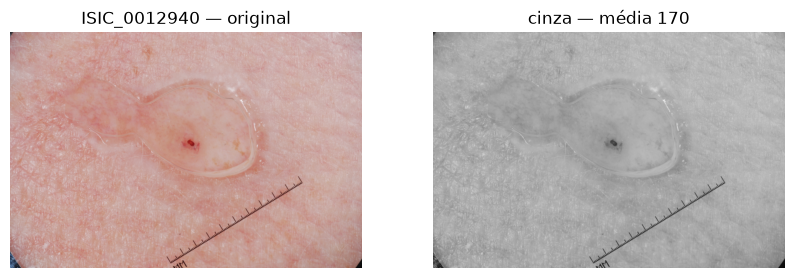

ISIC_0010206: shape (768, 1024) | diferença máx cv2 vs manual: 1


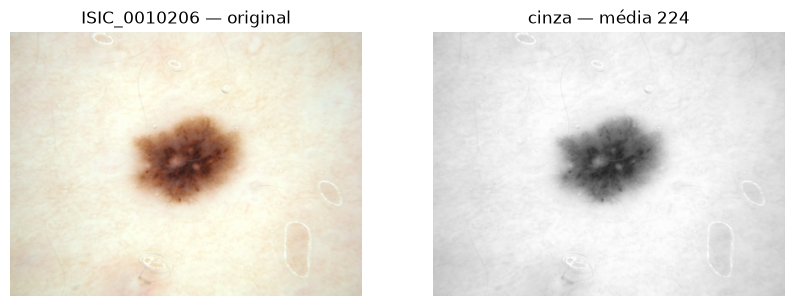

In [7]:
from src.preprocessamento import para_cinza, para_cinza_manual

alvo = PASTA_RESULTADOS / "cinza"

for nome in ["ISIC_0012940.jpg", "ISIC_0010206.jpg"]:
    img = carregar_imagem(PASTA_IMAGENS / nome)
    cinza = para_cinza(img)
    manual = para_cinza_manual(img)

    # validação: implementação própria vs OpenCV (diferença por arredondamento)
    dif = np.abs(cinza.astype(int) - manual.astype(int)).max()
    print(f"{Path(nome).stem}: shape {cinza.shape} | diferença máx cv2 vs manual: {dif}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img)
    axes[0].set_title(f"{Path(nome).stem} — original")
    axes[1].imshow(cinza, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title(f"cinza — média {cinza.mean():.0f}")
    for ax in axes:
        ax.axis("off")
    fig.savefig(alvo / f"{Path(nome).stem}_cinza.png", bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)